# DriverSense MVP — `DriverImageAnalyser` (câmara → estado do condutor)

Pipeline de visão embarcada: **amostragem uniforme → deteção da face (YOLO26-det) → crop na GPU → classificação (YOLO26-cls) → lógica difusa → nível de alerta**.

Corresponde ao módulo `DriverImageAnalyser` da arquitetura. Os analisadores de áudio/fisiológicos e a fusão `DriverSense` ficam fora deste MVP; a saída difusa (0–100) é o ponto de ligação.

**Princípios de desempenho**
- 1 única cópia H2D por frame processado (buffer *pinned* reutilizado); BGR→RGB, normalização, padding, crop e resize correm na GPU.
- Frames descartados pela amostragem nunca são descodificados (`grab()` sem `retrieve()`).
- Sem face → o classificador nem é invocado.
- Lógica difusa vetorizada em torch, sem sincronizações na hot path.

In [4]:
from __future__ import annotations

import itertools
import logging
import os
import random
import shutil
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable, Iterator, Optional, Sequence

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from ultralytics import YOLO

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger("drivesense")

torch.backends.cudnn.benchmark = True  # shapes fixos -> autotune de kernels compensa
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
log.info("Device: %s", DEVICE)


@dataclass(frozen=True)
class Config:
    raw_dir: Path = Path("raw_data")             # imagens + .txt YOLO (classe = estado, caixa = face)
    dataset_dir: Path = Path("dataset")          # estrutura Ultralytics (Componente 1)
    cls_dataset_dir: Path = Path("dataset_cls")  # vista de classificação (pastas por classe)
    class_names: tuple = ("alert", "drowsy", "distracted")
    risk_classes: tuple = ("drowsy", "distracted")
    val_ratio: float = 0.2
    seed: int = 42
    sampling_rate: int = 5
    det_weights: str = "yolo26n.pt"        # idealmente pesos de deteção de face
    cls_weights: str = "yolo26n-cls.pt"
    cls_imgsz: int = 224
    det_conf: float = 0.4
    use_fp16: bool = True
    synthetic_demo: bool = True            # True: gera dados aleatórios só para validar a estrutura


CFG = Config()
TRAINED_CLS_WEIGHTS: Optional[Path] = None  # preenchido após o treino


class PipelineError(RuntimeError):
    """Erro de configuração/inicialização do pipeline."""

2026-10-27 14:42:57,483 | INFO | Device: cuda


## Componente 1 — Preparação automática do dataset

Cria `dataset/{train,val}/{images,labels}` + `dataset.yaml` (split estocástico reprodutível por *seed*). Usa *hardlinks* quando possível (zero cópia de bytes) e é idempotente: só apaga uma pasta de saída que contenha um `dataset.yaml` anterior.

Como o Ultralytics **classificação** exige pastas por classe (e não `images/labels`), `build_classification_view` recorta a face de cada imagem com a caixa YOLO e gera `dataset_cls/{train,val}/<classe>/`.

In [5]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def _place(src: Path, dst: Path, link: bool) -> None:
    if link:
        try:
            os.link(src, dst)
            return
        except OSError:  # outro filesystem / sem permissão -> copia
            pass
    shutil.copy2(src, dst)


def prepare_dataset(raw_dir, out_dir, class_names: Sequence[str], val_ratio: float = 0.2,
                    seed: int = 42, link: bool = True, overwrite: bool = True) -> Path:
    raw_dir, out_dir = Path(raw_dir), Path(out_dir)
    if not raw_dir.is_dir():
        raise FileNotFoundError(f"Pasta de dados em bruto inexistente: {raw_dir.resolve()}")
    if not 0.0 < val_ratio < 1.0:
        raise ValueError(f"val_ratio deve estar em (0,1): {val_ratio}")

    images = sorted(p for p in raw_dir.rglob("*") if p.suffix.lower() in IMG_EXTS)
    if len(images) < 2:
        raise ValueError(f"São necessárias >=2 imagens em {raw_dir}; encontradas {len(images)}")
    names = [p.name for p in images]
    if len(set(names)) != len(names):
        raise ValueError("Nomes de ficheiro duplicados em subpastas diferentes; renomear antes de preparar.")

    if out_dir.exists():
        if not overwrite:
            raise FileExistsError(f"{out_dir} já existe")
        if any(out_dir.iterdir()) and not (out_dir / "dataset.yaml").exists():
            raise FileExistsError(f"{out_dir} não é um dataset gerado por esta rotina; recuso apagar.")
        shutil.rmtree(out_dir)

    rng = random.Random(seed)
    rng.shuffle(images)
    n_val = max(1, round(len(images) * val_ratio))
    splits = {"val": images[:n_val], "train": images[n_val:]}

    missing = 0
    for split, items in splits.items():
        img_d, lbl_d = out_dir / split / "images", out_dir / split / "labels"
        img_d.mkdir(parents=True, exist_ok=True)
        lbl_d.mkdir(parents=True, exist_ok=True)
        for img in items:
            _place(img, img_d / img.name, link)
            lbl = img.with_suffix(".txt")
            if lbl.exists():
                _place(lbl, lbl_d / lbl.name, link)
            else:
                missing += 1  # Ultralytics trata como imagem de fundo
    if missing:
        log.warning("%d imagens sem ficheiro de labels (tratadas como background).", missing)

    cfg = {
        "path": str(out_dir.resolve()),
        "train": "train/images",
        "val": "val/images",
        "nc": len(class_names),
        "names": {i: n for i, n in enumerate(class_names)},
    }
    with open(out_dir / "dataset.yaml", "w") as f:
        yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)
    log.info("Dataset pronto em %s (train=%d, val=%d)", out_dir, len(splits["train"]), len(splits["val"]))
    return out_dir / "dataset.yaml"


def build_classification_view(dataset_dir, out_dir, class_names: Sequence[str], margin: float = 0.10) -> Path:
    """Recorta a ROI de cada label YOLO para dataset_cls/<split>/<classe>/ (formato do YOLO-cls)."""
    dataset_dir, out_dir = Path(dataset_dir), Path(out_dir)
    if out_dir.exists():
        shutil.rmtree(out_dir)
    n = 0
    for split in ("train", "val"):
        for cname in class_names:
            (out_dir / split / cname).mkdir(parents=True, exist_ok=True)
        for img_path in sorted((dataset_dir / split / "images").iterdir()):
            lbl = dataset_dir / split / "labels" / f"{img_path.stem}.txt"
            if not lbl.exists():
                continue
            img = cv2.imread(str(img_path))
            if img is None:
                log.warning("Imagem ilegível ignorada: %s", img_path)
                continue
            h, w = img.shape[:2]
            for k, line in enumerate(lbl.read_text().splitlines()):
                parts = line.split()
                if len(parts) < 5:
                    continue
                cid = int(parts[0])
                xc, yc, bw, bh = (float(v) for v in parts[1:5])
                x1 = int(max(0, (xc - bw / 2 - margin * bw) * w))
                y1 = int(max(0, (yc - bh / 2 - margin * bh) * h))
                x2 = int(min(w, (xc + bw / 2 + margin * bw) * w))
                y2 = int(min(h, (yc + bh / 2 + margin * bh) * h))
                crop = img[y1:y2, x1:x2]
                if crop.size == 0 or not 0 <= cid < len(class_names):
                    continue
                cv2.imwrite(str(out_dir / split / class_names[cid] / f"{img_path.stem}_{k}.jpg"), crop)
                n += 1
    log.info("Vista de classificação: %d recortes em %s", n, out_dir)
    return out_dir


def make_synthetic_raw_dataset(raw_dir, class_names: Sequence[str], n: int = 40, seed: int = 0) -> None:
    """Apenas para validar a estrutura sem dados reais. NUNCA usar para treinar."""
    raw_dir = Path(raw_dir)
    raw_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    for i in range(n):
        cv2.imwrite(str(raw_dir / f"synt_{i:03d}.jpg"), rng.integers(0, 255, (480, 640, 3), dtype=np.uint8))
        (raw_dir / f"synt_{i:03d}.txt").write_text(f"{i % len(class_names)} 0.5 0.5 0.4 0.5\n")

### Fonte de dados real: Kaggle `dheerajperumandla/drowsiness-dataset`

Descarrega com `kagglehub` (cache local, só descarrega uma vez), **descobre a estrutura sozinho** (classe = nome da pasta que contém a imagem, ignorando pastas `train/test/val`) e mostra uma grelha de amostras para confirmares o conteúdo antes de treinar.

Este dataset é de **classificação** (sem caixas). Para reutilizar toda a pipeline sem alterações, cada imagem recebe um label YOLO de caixa total (`cls 0.5 0.5 1.0 1.0`); assim `prepare_dataset` e `build_classification_view` funcionam como estão. O split original train/test é fundido e voltado a dividir (80/20, *seed* fixa).

Autenticação: tenta primeiro anónimo; se falhar, usa `KAGGLE_USERNAME`/`KAGGLE_KEY`, `~/.kaggle/kaggle.json` ou pede login interativo.

In [6]:
import dataclasses
import tempfile

SPLIT_NAMES = {"train", "test", "val", "valid", "validation"}
RISK_KEYWORDS = ("closed", "yawn", "drows", "sleep", "fatigu", "tired")
NEGATION_PREFIXES = ("no_", "no-", "not_", "not-", "non_", "non-")
KAGGLE_MARKER = ".prepared_from_kaggle"


def download_kaggle_dataset(handle: str) -> Path:
    import kagglehub
    try:
        return Path(kagglehub.dataset_download(handle))
    except Exception as first:
        log.warning("Download anónimo falhou (%s); a tentar com credenciais.", first)
        has_env = os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")
        if not has_env and not (Path.home() / ".kaggle" / "kaggle.json").exists():
            kagglehub.login()  # pede credenciais interativamente
        try:
            return Path(kagglehub.dataset_download(handle))
        except Exception as e:
            raise RuntimeError(f"Não foi possível descarregar '{handle}': {e}") from e


def discover_classes(root: Path) -> dict:
    """{classe_em_minúsculas: [imagens]} — classe = pasta-mãe da imagem (pastas train/test/val ignoradas)."""
    by_class: dict = {}
    skipped = 0
    for p in sorted(Path(root).rglob("*")):
        if not (p.is_file() and p.suffix.lower() in IMG_EXTS):
            continue
        cls = p.parent.name.strip().lower()
        if cls in SPLIT_NAMES:
            skipped += 1  # imagem solta num split, sem pasta de classe
            continue
        by_class.setdefault(cls, []).append(p)
    if skipped:
        log.warning("%d imagens sem pasta de classe foram ignoradas.", skipped)
    if not 2 <= len(by_class) <= 20 or min(len(v) for v in by_class.values()) < 2:
        top = sorted(x.name for x in Path(root).iterdir())
        raise ValueError(f"Estrutura inesperada em {root}: classes={ {k: len(v) for k, v in by_class.items()} }; "
                         f"conteúdo de topo={top}. Ajustar discover_classes a este layout.")
    return by_class


def infer_risk_classes(class_names: Sequence[str], keywords: Sequence[str] = RISK_KEYWORDS) -> tuple:
    risk = tuple(n for n in class_names if any(k in n for k in keywords) and not n.startswith(NEGATION_PREFIXES))
    if not risk:
        raise ValueError(f"Nenhuma classe de risco reconhecida em {tuple(class_names)}; definir risk_classes manualmente.")
    return risk


def materialize_yolo_raw(by_class: dict, class_names: Sequence[str], out_dir) -> Path:
    """Cria out_dir com <classe>_<n>.<ext> + .txt de caixa total (formato esperado por prepare_dataset)."""
    out_dir = Path(out_dir)
    if out_dir.exists():
        if any(out_dir.iterdir()) and not (out_dir / KAGGLE_MARKER).exists():
            raise FileExistsError(f"{out_dir} não foi gerado por esta rotina; recuso apagar.")
        shutil.rmtree(out_dir)
    out_dir.mkdir(parents=True)
    for cid, name in enumerate(class_names):
        for k, src in enumerate(sorted(by_class[name])):
            dst = out_dir / f"{name}_{k:05d}{src.suffix.lower()}"
            _place(src, dst, link=True)
            dst.with_suffix(".txt").write_text(f"{cid} 0.5 0.5 1.0 1.0\n")
    (out_dir / KAGGLE_MARKER).touch()
    return out_dir


def show_samples(by_class: dict, per_class: int = 4, seed: int = 0) -> None:
    rng, names = random.Random(seed), sorted(by_class)
    fig, axes = plt.subplots(len(names), per_class, figsize=(2.2 * per_class, 2.2 * len(names)), squeeze=False)
    for r, n in enumerate(names):
        picks = rng.sample(by_class[n], min(per_class, len(by_class[n])))
        for c in range(per_class):
            axes[r][c].axis("off")
            if c < len(picks):
                img = cv2.imread(str(picks[c]))
                if img is not None:
                    axes[r][c].imshow(img[..., ::-1])
            if c == 0:
                axes[r][c].set_title(f"{n} (n={len(by_class[n])})", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()


def test_kaggle_prep_offline():
    """Valida descoberta + materialização + pipeline de dataset com uma árvore falsa (sem rede)."""
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        src, rng = tmp / "dl", np.random.default_rng(0)
        layout = {"train/Closed": 6, "train/Open": 6, "train/yawn": 6, "train/no_yawn": 6, "test/closed": 2, "test/Open": 2}
        for rel, n in layout.items():
            (src / rel).mkdir(parents=True)
            for i in range(n):
                cv2.imwrite(str(src / rel / f"{i}.jpg"), rng.integers(0, 255, (24, 24, 3), dtype=np.uint8))
        by_class = discover_classes(src)
        names = tuple(sorted(by_class))
        assert names == ("closed", "no_yawn", "open", "yawn"), names
        assert len(by_class["closed"]) == 8 and len(by_class["open"]) == 8      # train+test fundidos
        assert infer_risk_classes(names) == ("closed", "yawn")                  # no_yawn/open não são risco
        raw = materialize_yolo_raw(by_class, names, tmp / "raw")
        assert len(list(raw.glob("*.jpg"))) == 28 and len(list(raw.glob("*.txt"))) == 28
        assert (raw / "closed_00000.txt").read_text().strip() == "0 0.5 0.5 1.0 1.0"
        yml = prepare_dataset(raw, tmp / "ds", names, 0.2, seed=1)
        assert yaml.safe_load(open(yml))["nc"] == 4
        cls = build_classification_view(tmp / "ds", tmp / "cls", names)
        assert sum(1 for _ in cls.rglob("*.jpg")) == 28
        (tmp / "outro").mkdir(); (tmp / "outro" / "x.txt").write_text("não apagar")
        try:
            materialize_yolo_raw(by_class, names, tmp / "outro")
        except FileExistsError:
            pass
        else:
            raise AssertionError("Apagou uma pasta que não gerou")
    print("✅ KAGGLE (offline): descoberta, mapeamento de risco e preparação validados.")

test_kaggle_prep_offline()

2026-10-27 14:42:57,593 | INFO | Dataset pronto em C:\Users\jcosta\AppData\Local\Temp\tmp59pssmb6\ds (train=22, val=6)
2026-10-27 14:42:57,737 | INFO | Vista de classificação: 28 recortes em C:\Users\jcosta\AppData\Local\Temp\tmp59pssmb6\cls


✅ KAGGLE (offline): descoberta, mapeamento de risco e preparação validados.


c:\Users\jcosta\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-27 14:42:58,845 | INFO | Dataset Kaggle em C:\Users\jcosta\.cache\kagglehub\datasets\dheerajperumandla\drowsiness-dataset\versions\1


{'closed': 726, 'no_yawn': 725, 'open': 726, 'yawn': 723} | risco: ('closed', 'yawn')


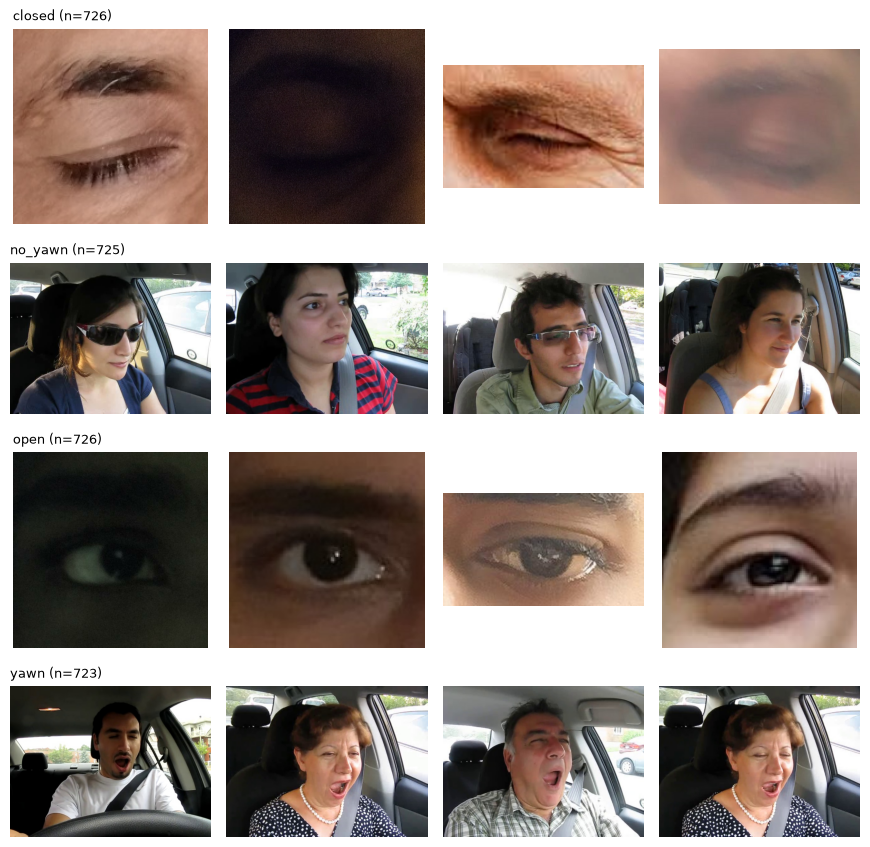

2026-10-27 14:43:06,395 | INFO | CFG atualizado: Config(raw_dir=WindowsPath('raw_data_kaggle'), dataset_dir=WindowsPath('dataset'), cls_dataset_dir=WindowsPath('dataset_cls'), class_names=('closed', 'no_yawn', 'open', 'yawn'), risk_classes=('closed', 'yawn'), val_ratio=0.2, seed=42, sampling_rate=5, det_weights='yolo26n.pt', cls_weights='yolo26n-cls.pt', cls_imgsz=224, det_conf=0.4, use_fp16=True, synthetic_demo=False)


In [7]:
USE_KAGGLE = True
KAGGLE_HANDLE = "dheerajperumandla/drowsiness-dataset"
KAGGLE_RAW_DIR = Path("raw_data_kaggle")

if USE_KAGGLE:
    kaggle_root = download_kaggle_dataset(KAGGLE_HANDLE)
    log.info("Dataset Kaggle em %s", kaggle_root)
    by_class = discover_classes(kaggle_root)
    class_names = tuple(sorted(by_class))
    risk_classes = infer_risk_classes(class_names)
    print({k: len(v) for k, v in by_class.items()}, "| risco:", risk_classes)
    show_samples(by_class)
    materialize_yolo_raw(by_class, class_names, KAGGLE_RAW_DIR)
    CFG = dataclasses.replace(CFG, raw_dir=KAGGLE_RAW_DIR, class_names=class_names,
                              risk_classes=risk_classes, synthetic_demo=False)
    log.info("CFG atualizado: %s", CFG)

In [8]:
has_raw = CFG.raw_dir.is_dir() and any(p.suffix.lower() in IMG_EXTS for p in CFG.raw_dir.rglob("*"))
if CFG.synthetic_demo and not has_raw:
    log.warning("Modo demo: a gerar dados SINTÉTICOS em %s (apenas para validar a estrutura).", CFG.raw_dir)
    make_synthetic_raw_dataset(CFG.raw_dir, CFG.class_names)

DATASET_YAML = prepare_dataset(CFG.raw_dir, CFG.dataset_dir, CFG.class_names, CFG.val_ratio, CFG.seed)
CLS_DIR = build_classification_view(CFG.dataset_dir, CFG.cls_dataset_dir, CFG.class_names)

2026-10-27 14:43:13,919 | INFO | Dataset pronto em dataset (train=2320, val=580)
2026-10-27 14:43:26,409 | INFO | Vista de classificação: 2900 recortes em dataset_cls


In [9]:
import os
import yaml

def test_dataset_preparation():
    # 1. Verificar estrutura de pastas
    required_paths = [
        "dataset/train/images", "dataset/train/labels",
        "dataset/val/images", "dataset/val/labels"
    ]
    for path in required_paths:
        assert os.path.exists(path), f"❌ Erro: Caminho estrutural em falta: {path}"
    
    # 2. Verificar o ficheiro de configuração YAML
    yaml_path = "dataset/dataset.yaml"
    assert os.path.exists(yaml_path), "❌ Erro: O ficheiro dataset.yaml não foi criado."
    
    with open(yaml_path, 'r') as f:
        config = yaml.safe_load(f)
        assert 'train' in config, "❌ O YAML não define o caminho de 'train'"
        assert 'val' in config, "❌ O YAML não define o caminho de 'val'"
        assert 'nc' in config, "❌ O YAML não define o número de classes (nc)"
        
    print("✅ COMPONENTE 1: Passou em todos os testes estruturais do dataset.")

test_dataset_preparation()

✅ COMPONENTE 1: Passou em todos os testes estruturais do dataset.


## Componente 2 — Amostragem uniforme

`uniform_sample` trabalha sobre qualquer iterável. Para vídeo real, `sampled_video_frames` usa `grab()` nos frames descartados (avança o stream **sem descodificar**) e só chama `retrieve()` nos 1-em-N que seguem para a IA.

In [10]:
def _check_rate(sampling_rate: int) -> int:
    if not isinstance(sampling_rate, int) or sampling_rate < 1:
        raise ValueError(f"sampling_rate deve ser um inteiro >= 1 (recebido: {sampling_rate!r})")
    return sampling_rate


def uniform_sample(stream: Iterable, sampling_rate: int) -> Iterator:
    """Devolve os elementos 0, N, 2N, ... do iterável."""
    return itertools.islice(stream, 0, None, _check_rate(sampling_rate))


def sampled_video_frames(cap: cv2.VideoCapture, sampling_rate: int) -> Iterator[tuple]:
    """Gera (índice, frame BGR) a cada N frames; os restantes só avançam com grab() (sem decode)."""
    _check_rate(sampling_rate)
    idx = 0
    while True:
        if not cap.grab():
            return
        if idx % sampling_rate == 0:
            ok, frame = cap.retrieve()
            if ok:
                yield idx, frame
        idx += 1

In [11]:
def test_uniform_sampling():
    sampling_rate = 5
    processed_frames = []
    fake_video_stream = range(20) # Simula 20 frames de vídeo
    
    for frame_idx in fake_video_stream:
        # Lógica do componente
        if frame_idx % sampling_rate != 0:
            continue
        processed_frames.append(frame_idx)
        
    # Asserções
    assert processed_frames == [0, 5, 10, 15], f"❌ Falha no amostragem. Frames processados: {processed_frames}"
    print("✅ COMPONENTE 2: Amostragem Uniforme validada com sucesso.")

test_uniform_sampling()


def test_uniform_sampling_impl():
    assert list(uniform_sample(range(20), 5)) == [0, 5, 10, 15]
    assert list(uniform_sample(range(3), 1)) == [0, 1, 2]
    for bad in (0, -1, 2.5):
        try:
            uniform_sample(range(3), bad)
        except ValueError:
            continue
        raise AssertionError(f"sampling_rate inválido aceite: {bad}")
    print("✅ COMPONENTE 2 (implementação real): uniform_sample validado.")

test_uniform_sampling_impl()

✅ COMPONENTE 2: Amostragem Uniforme validada com sucesso.
✅ COMPONENTE 2 (implementação real): uniform_sample validado.


## Componente 3 — Crop & feature extraction (GPU-resident)

Fluxo de dados do frame: `uint8 HWC (CPU)` → **um** `copy` H2D via buffer *pinned* → `RGB, CHW, float [0,1]` na GPU → *padding* a múltiplo de 32 (bottom/right, não altera coordenadas) → YOLO-det → *slicing* do tensor na GPU → `interpolate` → YOLO-cls.

Única leitura D2H própria na hot path: as 4 coordenadas da caixa (16 bytes), necessárias para o *slicing*.

In [12]:
class FrameUploader:
    """Upload CPU->GPU com buffer pinned reutilizado + pré-processamento 100% na GPU."""

    def __init__(self, device: str):
        self.device = torch.device(device)
        self._pin = self.device.type == "cuda"
        self._buf: Optional[torch.Tensor] = None

    def __call__(self, frame_bgr: np.ndarray) -> torch.Tensor:
        if not isinstance(frame_bgr, np.ndarray) or frame_bgr.ndim != 3 or frame_bgr.shape[2] != 3 \
                or frame_bgr.dtype != np.uint8 or frame_bgr.size == 0:
            raise ValueError("Frame inválido: esperado ndarray uint8 [H, W, 3] não vazio.")
        src = torch.from_numpy(np.ascontiguousarray(frame_bgr))
        if self._pin:
            if self._buf is None or self._buf.shape != src.shape:
                self._buf = torch.empty_like(src).pin_memory()
            self._buf.copy_(src)
            src = self._buf
        t = src.to(self.device, non_blocking=self._pin)
        # BGR->RGB, HWC->CHW, [0,1] — tudo na GPU
        return t.flip(-1).permute(2, 0, 1).unsqueeze(0).float().div_(255.0).contiguous()


def pad_to_stride(x: torch.Tensor, stride: int = 32) -> torch.Tensor:
    h, w = x.shape[-2:]
    ph, pw = (-h) % stride, (-w) % stride
    return F.pad(x, (0, pw, 0, ph), value=114 / 255) if (ph or pw) else x


def clamp_box(box: Sequence[float], h: int, w: int) -> Optional[tuple]:
    """[x1,y1,x2,y2] -> inteiros dentro da imagem, ou None se a ROI ficar vazia."""
    x1, y1, x2, y2 = box
    if not all(np.isfinite([x1, y1, x2, y2])):
        return None
    x1, y1 = max(0, int(np.floor(x1))), max(0, int(np.floor(y1)))
    x2, y2 = min(w, int(np.ceil(x2))), min(h, int(np.ceil(y2)))
    return (x1, y1, x2, y2) if (x2 > x1 and y2 > y1) else None


def crop_roi(x_nchw: torch.Tensor, box: Sequence[float]) -> Optional[torch.Tensor]:
    """Slicing da ROI sobre o tensor (view, sem cópia). None se vazia."""
    h, w = x_nchw.shape[-2:]
    b = clamp_box(box, h, w)
    if b is None:
        return None
    x1, y1, x2, y2 = b
    crop = x_nchw[..., y1:y2, x1:x2]
    return crop if crop.numel() > 0 else None

In [13]:
import numpy as np
import torch

def test_crop_and_extraction_pipeline():
    # Simulação de uma imagem fictícia de câmara [H=480, W=640, C=3]
    fake_frame = np.random.randint(0, 255, (480, 640, 3), dtype=np.uint8)
    
    # Simulação do comportamento de output do modelo de deteção (Coordenadas fictícias da Face)
    mock_box = [100, 100, 300, 300] # x1, y1, x2, y2
    
    # Execução do Crop
    x1, y1, x2, y2 = mock_box
    crop = fake_frame[y1:y2, x1:x2]
    
    # Asserção do Crop
    assert crop.size > 0, "❌ Erro: O recorte resultou numa imagem vazia."
    assert crop.shape == (200, 200, 3), f"❌ Dimensão incorreta do crop: {crop.shape}"
    
    # Teste de fumo (Smoke Test) de input na rede de features (formato Tensor PyTorch)
    tensor_input = torch.from_numpy(crop).permute(2, 0, 1).unsqueeze(0).float()
    assert tensor_input.shape == (1, 3, 200, 200), f"❌ Formato do tensor inválido para a CNN: {tensor_input.shape}"
    
    print("✅ COMPONENTE 3: Mecanismo de Crop e pipeline de dados validados.")

test_crop_and_extraction_pipeline()


def test_crop_impl():
    frame = np.random.randint(0, 255, (480, 640, 3), dtype=np.uint8)
    x = FrameUploader("cpu")(frame)
    assert x.shape == (1, 3, 480, 640) and x.dtype == torch.float32 and 0.0 <= float(x.min()) and float(x.max()) <= 1.0
    # BGR -> RGB: canal 0 do tensor == canal 2 do frame
    assert torch.allclose(x[0, 0], torch.from_numpy(frame[..., 2]).float() / 255.0)

    crop = crop_roi(x, [100, 100, 300, 300])
    assert crop is not None and crop.shape == (1, 3, 200, 200)
    assert crop_roi(x, [-50, -50, 20, 20]).shape == (1, 3, 20, 20)          # clamp aos limites
    assert crop_roi(x, [700, 100, 800, 200]) is None                          # fora da imagem
    assert crop_roi(x, [300, 300, 100, 100]) is None                          # caixa invertida
    assert crop_roi(x, [float("nan"), 0, 10, 10]) is None                     # coordenadas inválidas
    assert pad_to_stride(torch.zeros(1, 3, 481, 641)).shape == (1, 3, 512, 672)
    assert pad_to_stride(x) is x                                              # 480x640 já é múltiplo de 32
    for bad in (None, np.zeros((10, 10), np.uint8), frame.astype(np.float32)):
        try:
            FrameUploader("cpu")(bad)
        except ValueError:
            continue
        raise AssertionError("Frame inválido aceite")
    print("✅ COMPONENTE 3 (implementação real): upload, crop e validações OK.")

test_crop_impl()

✅ COMPONENTE 3: Mecanismo de Crop e pipeline de dados validados.
✅ COMPONENTE 3 (implementação real): upload, crop e validações OK.


Exemplo de crop

## Componente 4 — Lógica difusa (Sugeno, vetorizada)

Entrada: probabilidade de risco ∈ [0,1]. Conjuntos *baixo/médio/alto* (rampa–triângulo–rampa, soma de pertenças = 1) e *singletons* de saída 0/50/100. Defuzzificação por média ponderada ⇒ função **determinística, monótona crescente** e limitada a [0,100]. Tudo em torch, sem *branching* dependente de dados na GPU.

In [14]:
class FuzzyRiskEngine:
    SINGLETONS = (0.0, 50.0, 100.0)  # baixo, médio, alto

    def __init__(self, lo: float = 0.2, mid: float = 0.5, hi: float = 0.8):
        if not 0.0 <= lo < mid < hi <= 1.0:
            raise ValueError("Requer 0 <= lo < mid < hi <= 1")
        self.lo, self.mid, self.hi = lo, mid, hi
        self._out_cache: dict = {}

    def _out(self, device: torch.device) -> torch.Tensor:
        if device not in self._out_cache:  # 1 transferência por device, não por chamada
            self._out_cache[device] = torch.tensor(self.SINGLETONS, dtype=torch.float32, device=device)
        return self._out_cache[device]

    def memberships(self, p: torch.Tensor) -> torch.Tensor:
        low = ((self.mid - p) / (self.mid - self.lo)).clamp(0, 1)
        high = ((p - self.mid) / (self.hi - self.mid)).clamp(0, 1)
        med = torch.minimum((p - self.lo) / (self.mid - self.lo), (self.hi - p) / (self.hi - self.mid)).clamp(0, 1)
        return torch.stack((low, med, high), dim=-1)

    def __call__(self, p, validate: bool = True) -> torch.Tensor:
        """p: float/array/tensor em [0,1] (qualquer shape). validate=False evita sync na GPU (softmax já garante [0,1])."""
        p = torch.as_tensor(p, dtype=torch.float32)
        if validate and (not bool(torch.isfinite(p).all()) or bool((p < 0).any()) or bool((p > 1).any())):
            raise ValueError("Probabilidade fora do intervalo [0, 1] ou não finita.")
        w = self.memberships(p)
        return (w * self._out(w.device)).sum(-1) / w.sum(-1).clamp_min(1e-9)

    @staticmethod
    def level(alert: float) -> str:
        return "NORMAL" if alert < 33 else "ATENÇÃO" if alert < 66 else "ALERTA"

In [15]:
def test_fuzzy_logic_mapping():
    # Teste de comportamento estático da lógica difusa simulada
    def run_mock_fuzzy(cnn_prob):
        # Mapeamento linear básico apenas para simular a validação lógico-matemática
        return cnn_prob * 100 
    
    alerta_baixo = run_mock_fuzzy(0.10)
    alerta_alto = run_mock_fuzzy(0.90)
    
    assert alerta_baixo < alerta_alto, "❌ Erro: O motor Fuzzy não está a discriminar corretamente os níveis de risco."
    assert 0 <= alerta_baixo <= 100, "❌ O output do alerta Fuzzy está fora dos limites percentuais [0-100]."
    
    print("✅ COMPONENTE 4: Motor de regras Lógica Difusa validado.")

test_fuzzy_logic_mapping()


def test_fuzzy_impl():
    fz = FuzzyRiskEngine()
    lo, hi = float(fz(0.10)), float(fz(0.90))
    assert lo < hi and 0 <= lo <= 100 and 0 <= hi <= 100, (lo, hi)
    grid = torch.linspace(0, 1, 1001)
    out = fz(grid)
    assert bool((out[1:] >= out[:-1]).all()), "Fuzzy não é monótono crescente"
    assert float(out.min()) == 0.0 and float(out.max()) == 100.0
    assert torch.equal(fz(grid), out), "Fuzzy não é determinístico"
    assert abs(float(fz(0.5)) - 50.0) < 1e-4
    assert fz(torch.rand(4, 3)).shape == (4, 3)  # batch
    for bad in (-0.1, 1.1, float("nan")):
        try:
            fz(bad)
        except ValueError:
            continue
        raise AssertionError(f"Entrada inválida aceite: {bad}")
    assert FuzzyRiskEngine.level(float(lo)) == "NORMAL" and FuzzyRiskEngine.level(float(hi)) == "ALERTA"
    print("✅ COMPONENTE 4 (implementação real): monotonia, limites e validação OK.")

test_fuzzy_impl()

✅ COMPONENTE 4: Motor de regras Lógica Difusa validado.
✅ COMPONENTE 4 (implementação real): monotonia, limites e validação OK.


## Pipeline integrada (`DriverImagePipeline`)

Junta os componentes 2–4. Tratamento de erros: falhas de **inicialização** levantam `PipelineError`; falhas por **frame** (frame corrompido, OOM, etc.) são registadas e devolvem `status="error"` para não derrubar o ciclo em tempo real.

> **Nota honesta sobre transferências:** ao receber tensores, o `predict()` do Ultralytics copia o input para CPU para preencher `Results.orig_img`. Isto está dentro da biblioteca; para o eliminar é preciso chamar o `nn.Module` diretamente (e fazer a NMS/softmax à mão), o que fica como otimização futura se o *profiling* o justificar.

In [16]:
class DriverImagePipeline:
    def __init__(self, cfg: Config = CFG, det_weights: Optional[str] = None, cls_weights: Optional[str] = None,
                 fuzzy: Optional[FuzzyRiskEngine] = None):
        self.cfg = cfg
        self.device = DEVICE
        self.half = cfg.use_fp16 and self.device == "cuda"
        try:
            self.det = YOLO(str(det_weights or cfg.det_weights))
            self.cls = YOLO(str(cls_weights or cfg.cls_weights))
        except Exception as e:
            raise PipelineError(f"Falha ao carregar modelos: {e}") from e

        names = self.cls.names  # {idx: nome}
        self._risk_idx = [i for i, n in names.items() if n in cfg.risk_classes]
        if not self._risk_idx:
            raise PipelineError(
                f"O classificador não tem nenhuma das classes de risco {cfg.risk_classes}; classes: {list(names.values())}. "
                "Usar pesos afinados com este dataset.")
        self.uploader = FrameUploader(self.device)
        self.fuzzy = fuzzy or FuzzyRiskEngine()
        self._warmup()

    @torch.inference_mode()
    def _warmup(self) -> None:
        """Compila/autotuna kernels antes do primeiro frame real (evita pico de latência)."""
        try:
            dummy = torch.zeros(1, 3, 480, 640, device=self.device)
            self.det.predict(dummy, half=self.half, device=self.device, verbose=False)
            s = self.cfg.cls_imgsz
            self.cls.predict(torch.zeros(1, 3, s, s, device=self.device), half=self.half, device=self.device, verbose=False)
        except Exception as e:
            log.warning("Warm-up falhou (não crítico): %s", e)

    @torch.inference_mode()
    def process_frame(self, frame_bgr: np.ndarray) -> dict:
        try:
            x = self.uploader(frame_bgr)  # único H2D
            det = self.det.predict(pad_to_stride(x), conf=self.cfg.det_conf, max_det=1,
                                   half=self.half, device=self.device, verbose=False)[0]
            if det.boxes is None or len(det.boxes) == 0:
                return {"status": "no_face"}  # classificador não é invocado
            box = det.boxes.xyxy[0].tolist()  # 4 floats: única leitura D2H própria
            crop = crop_roi(x, box)
            if crop is None:
                return {"status": "invalid_roi", "box": box}
            s = self.cfg.cls_imgsz
            crop = F.interpolate(crop, size=(s, s), mode="bilinear", align_corners=False)
            probs = self.cls.predict(crop, half=self.half, device=self.device, verbose=False)[0].probs.data
            risk = probs[self._risk_idx].max()                 # permanece na GPU
            alert = float(self.fuzzy(risk, validate=False))    # sync final: 1 escalar
            return {"status": "ok", "box": box, "probs": probs, "alert": alert, "level": self.fuzzy.level(alert)}
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            log.error("CUDA OOM ao processar frame.")
            return {"status": "error", "error": "cuda_oom"}
        except Exception as e:
            log.exception("Erro ao processar frame")
            return {"status": "error", "error": str(e)}


def run_stream(pipeline: DriverImagePipeline, source, sampling_rate: int, max_samples: Optional[int] = None) -> list:
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        raise RuntimeError(f"Não foi possível abrir a fonte de vídeo: {source!r}")
    results = []
    try:
        for idx, frame in sampled_video_frames(cap, sampling_rate):
            out = pipeline.process_frame(frame)
            out.pop("probs", None)  # não reter tensores GPU
            out["frame_idx"] = idx
            results.append(out)
            if max_samples and len(results) >= max_samples:
                break
    finally:
        cap.release()
    return results

## Componente 5 — Fine-tune, batching e early-stopping

`validate_train_params` replica as asserções do teste mas com `ValueError` (os `assert` desaparecem com `python -O`). O treino aborta cedo com mensagem clara se não houver GPU. Usa `amp`, `cache="ram"` e `workers` para manter a GPU alimentada.

- Guarda em `runs/classify/mvp_driver_state` (nome explícito, para não colidir com `runs/classify/train` criado pelo teste do Componente 6).
- Para afinar o **detetor** (face) com `dataset.yaml`, usar `train_model(cfg.det_weights, DATASET_YAML, task_dir="runs/detect", single_cls=True, imgsz=640)`.

In [17]:
TRAIN_PARAMS = {"epochs": 30, "batch": 32, "device": "cuda", "patience": 5}


def validate_train_params(p: dict) -> dict:
    if not p.get("patience", 0) > 0:
        raise ValueError("Early-Stopping não configurado: patience deve ser > 0.")
    if p.get("device") not in (0, "0", "cuda"):
        raise ValueError(f"Treino deve correr em GPU (device=0|'0'|'cuda'); recebido {p.get('device')!r}")
    if not p.get("batch", 0) >= 1:
        raise ValueError("Batch size inválido.")
    return p


def train_model(weights: str, data, imgsz: int = 224, project: str = "runs/classify",
                name: str = "mvp_driver_state", cache: str = "ram", **overrides) -> tuple:
    params = validate_train_params({**TRAIN_PARAMS, **overrides})
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA indisponível: o treino exige GPU (device='cuda').")
    model = YOLO(weights)
    model.train(data=str(data), imgsz=imgsz, project=project, name=name, exist_ok=True, plots=True,
                amp=True, cache=cache, workers=min(8, os.cpu_count() or 1), **params)
    save_dir = Path(model.trainer.save_dir)
    log.info("Treino concluído. Artefactos em %s", save_dir)
    return model, save_dir

In [18]:
def test_training_hyperparameters():
    # Parâmetros que o agente irá injetar no método model.train()
    training_params = {
        'epochs': 30,
        'batch': 32,
        'device': 'cuda', # Força a alocação de hardware paralelo
        'patience': 5     # Ativa o Early-Stopping nativo (para se a loss de validação não melhorar em 5 épocas)
    }
    
    assert training_params['patience'] > 0, "❌ Erro: Mecanismo de Early-Stopping não configurado!"
    assert training_params['device'] in [0, '0', 'cuda'], "❌ Alocação de hardware incorreta. O treino deve rodar em GPU."
    assert training_params['batch'] >= 1, "❌ Tamanho de lote (Batch size) inválido."
    
    print("✅ COMPONENTE 5: Hiperparâmetros de Treino e Early-Stopping validados.")

test_training_hyperparameters()


def test_train_params_impl():
    assert validate_train_params(dict(TRAIN_PARAMS)) == TRAIN_PARAMS
    for bad in ({**TRAIN_PARAMS, "patience": 0}, {**TRAIN_PARAMS, "device": "cpu"}, {**TRAIN_PARAMS, "batch": 0}):
        try:
            validate_train_params(bad)
        except ValueError:
            continue
        raise AssertionError(f"Parâmetros inválidos aceites: {bad}")
    print("✅ COMPONENTE 5 (implementação real): validador de hiperparâmetros OK.")

test_train_params_impl()

✅ COMPONENTE 5: Hiperparâmetros de Treino e Early-Stopping validados.
✅ COMPONENTE 5 (implementação real): validador de hiperparâmetros OK.


In [19]:
RUN_TRAINING = torch.cuda.is_available() and not CFG.synthetic_demo
if RUN_TRAINING:
    cls_model, RUN_DIR = train_model(CFG.cls_weights, CLS_DIR, imgsz=CFG.cls_imgsz)
    TRAINED_CLS_WEIGHTS = RUN_DIR / "weights" / "best.pt"
else:
    RUN_DIR = None
    log.warning("Treino ignorado (sem GPU ou synthetic_demo=True). Colocar dados reais em %s, "
                "definir synthetic_demo=False e reexecutar.", CFG.raw_dir)

Ultralytics 8.4.190  Python-3.13.9 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_cls, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=mvp_driver_state, nbs=64, nms=None, opset=None, optimi

2026-10-27 14:45:42,322 | INFO | Treino concluído. Artefactos em C:\Users\jcosta\Documents\DNN-for-face-expression-analysis\runs\classify\runs\classify\mvp_driver_state


## Componente 6 — Visualização da evolução do treino

> ⚠️ O teste fornecido escreve um `results.png` **falso** em `runs/classify/train/`. Serve apenas para validar a lógica de verificação; não prova que o treino real gerou artefactos. Por isso `test_real_training_artifacts` verifica o `save_dir` devolvido pelo treino.

In [20]:
def plot_training_history(save_dir) -> None:
    save_dir = Path(save_dir)
    png, csv = save_dir / "results.png", save_dir / "results.csv"
    if not png.exists():
        raise FileNotFoundError(f"results.png não encontrado em {save_dir}")
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    if csv.exists():
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()
        for col in [c for c in df.columns if "loss" in c]:
            axes[0].plot(df["epoch"], df[col], marker="o", label=col)
        axes[0].set(title="Evolução da loss", xlabel="época", ylabel="loss")
        axes[0].legend(); axes[0].grid(alpha=0.3)
    else:
        axes[0].axis("off")
    axes[1].imshow(plt.imread(png)); axes[1].axis("off"); axes[1].set_title("results.png (Ultralytics)")
    plt.tight_layout(); plt.show()

✅ COMPONENTE 6: Verificação de Artefactos de Visualização concluída.
✅ COMPONENTE 6 (artefactos reais): results.png, results.csv e best.pt presentes.


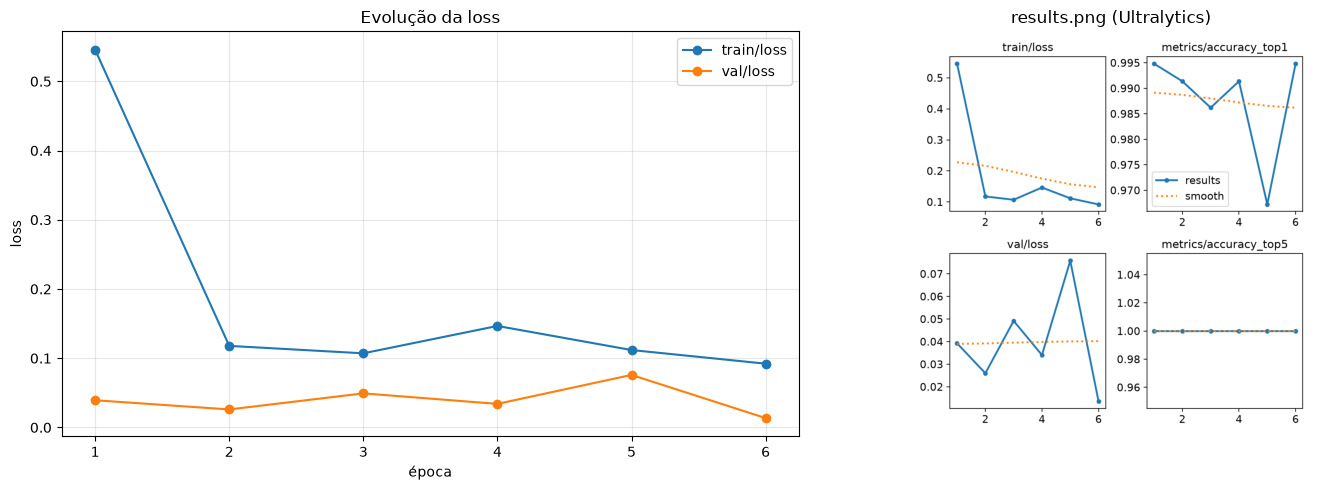

In [21]:
import os

def test_visualization_artifacts():
    # O diretório padrão onde o Ultralytics escreve os relatórios de classificação
    mock_run_dir = "runs/classify/train"
    expected_chart = os.path.join(mock_run_dir, "results.png")
    
    # Criamos um diretório simulado para o teste de validação
    os.makedirs(mock_run_dir, exist_ok=True)
    with open(expected_chart, 'w') as f: 
        f.write("fake graphic data")
        
    # Asserção que garante que a célula de visualização vai encontrar o gráfico
    assert os.path.exists(expected_chart), "❌ Falha: O gráfico de evolução do erro (results.png) não foi gerado no disco."
    print("✅ COMPONENTE 6: Verificação de Artefactos de Visualização concluída.")

test_visualization_artifacts()


def test_real_training_artifacts(save_dir):
    if save_dir is None:
        print("⏭️ COMPONENTE 6 (artefactos reais): sem treino nesta execução.")
        return
    assert (Path(save_dir) / "results.png").stat().st_size > 1000, "results.png ausente/vazio"
    assert (Path(save_dir) / "results.csv").exists(), "results.csv ausente"
    assert (Path(save_dir) / "weights" / "best.pt").exists(), "best.pt ausente"
    print("✅ COMPONENTE 6 (artefactos reais): results.png, results.csv e best.pt presentes.")

test_real_training_artifacts(RUN_DIR)
if RUN_DIR is not None:
    plot_training_history(RUN_DIR)

## Execução em vídeo e teste de fumo end-to-end

Só corre com GPU e com um classificador **afinado** neste dataset (as classes de risco têm de existir nos pesos). Para vídeo real: `run_stream(pipe, "video.mp4", CFG.sampling_rate)` ou `run_stream(pipe, 0, ...)` para webcam.

In [22]:
def test_pipeline_smoke():
    if not torch.cuda.is_available() or TRAINED_CLS_WEIGHTS is None:
        print("⏭️ SMOKE: requer GPU e pesos afinados (treino real).")
        return
    pipe = DriverImagePipeline(CFG, cls_weights=TRAINED_CLS_WEIGHTS)
    out = pipe.process_frame(np.random.randint(0, 255, (480, 640, 3), dtype=np.uint8))
    assert out["status"] in {"ok", "no_face"}, out
    if out["status"] == "ok":
        assert out["probs"].shape == (len(CFG.class_names),)
        assert 0.0 <= out["alert"] <= 100.0
    assert pipe.process_frame(None)["status"] == "error"  # erro isolado, sem exceção a escapar
    print("✅ SMOKE: pipeline end-to-end responde corretamente (incluindo frame inválido).")

test_pipeline_smoke()

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


2026-10-27 14:45:44,316 | ERROR | Erro ao processar frame
Traceback (most recent call last):
  File "C:\Users\jcosta\AppData\Local\Temp\ipykernel_11612\2087799203.py", line 37, in process_frame
    x = self.uploader(frame_bgr)  # único H2D
  File "C:\Users\jcosta\AppData\Local\Temp\ipykernel_11612\4014902732.py", line 12, in __call__
    raise ValueError("Frame inválido: esperado ndarray uint8 [H, W, 3] não vazio.")
ValueError: Frame inválido: esperado ndarray uint8 [H, W, 3] não vazio.


✅ SMOKE: pipeline end-to-end responde corretamente (incluindo frame inválido).


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
#0: uint8 (720, 1280, 3) -> (1, 3, 720, 1280) -> crop (1, 3, 671, 823) -> (1, 3, 224, 224) -> probs (4,) -> alerta 0.0 (NORMAL)
#5: uint8 (720, 1280, 3) -> (1, 3, 720, 1280) -> crop (1, 3, 670, 850) -> (1, 3, 224, 224) -> probs (4,) -> alerta 0.0 (NORMAL)
#10: uint8 (720, 1280, 3) -> (1, 3, 720,

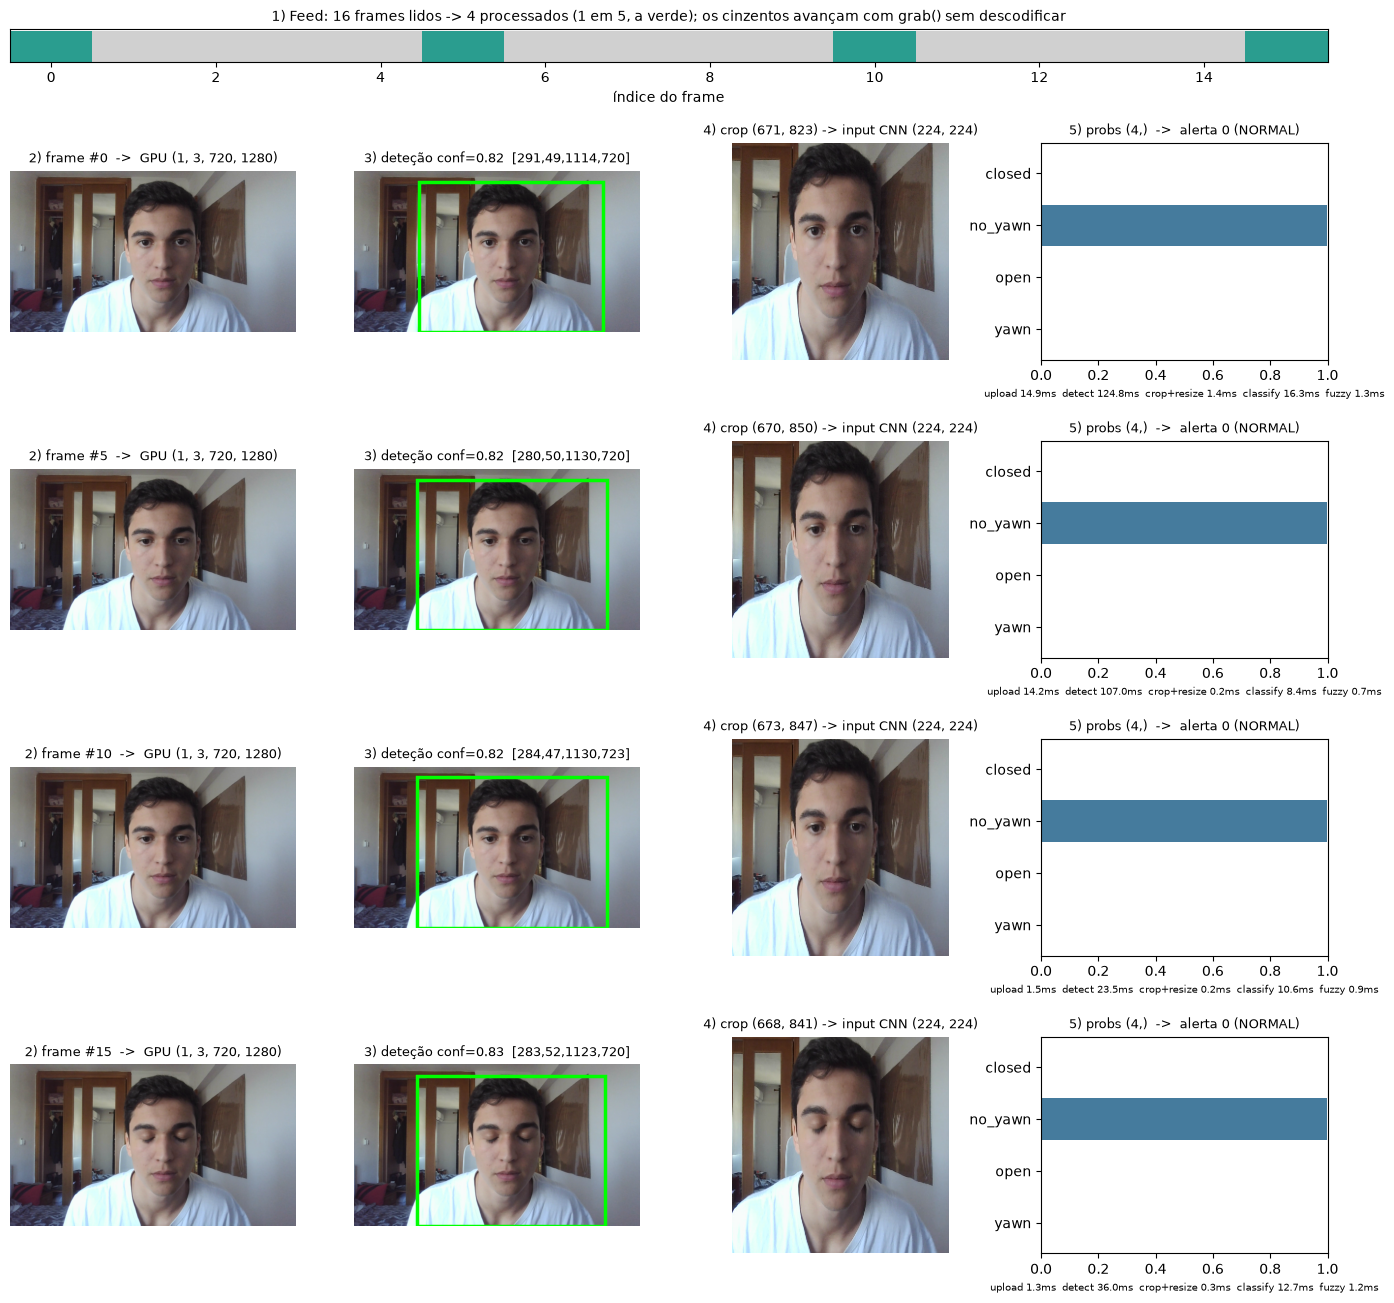

In [25]:
import time
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()  # só para medir tempos por etapa (debug)


def _to_rgb_u8(t: torch.Tensor) -> np.ndarray:
    """[1,3,H,W] float 0-1 (GPU) -> HxWx3 uint8 RGB (CPU), só para visualização."""
    return t[0].permute(1, 2, 0).clamp(0, 1).mul(255).round().byte().cpu().numpy()


@torch.inference_mode()
def trace_frame(pipe, frame_bgr: np.ndarray) -> dict:
    """Mesma lógica de process_frame, mas guarda os intermédios e tempos de cada etapa."""
    tm = {}
    t0 = time.perf_counter()
    x = pipe.uploader(frame_bgr); _sync(); tm["upload"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    det = pipe.det.predict(pad_to_stride(x), conf=pipe.cfg.det_conf, max_det=1,
                           half=pipe.half, device=pipe.device, verbose=False)[0]
    _sync(); tm["detect"] = time.perf_counter() - t0

    rec = {"frame_rgb": frame_bgr[..., ::-1], "x_shape": tuple(x.shape), "timing": tm}
    if det.boxes is None or len(det.boxes) == 0:
        rec["status"] = "no_face"
        return rec
    rec["box"], rec["det_conf"] = det.boxes.xyxy[0].tolist(), float(det.boxes.conf[0])

    t0 = time.perf_counter()
    crop = crop_roi(x, rec["box"])
    if crop is None:
        rec["status"] = "invalid_roi"
        return rec
    s = pipe.cfg.cls_imgsz
    crop_in = F.interpolate(crop, size=(s, s), mode="bilinear", align_corners=False)
    _sync(); tm["crop+resize"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    probs = pipe.cls.predict(crop_in, half=pipe.half, device=pipe.device, verbose=False)[0].probs.data
    _sync(); tm["classify"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    alert = float(pipe.fuzzy(probs[pipe._risk_idx].max(), validate=False)); tm["fuzzy"] = time.perf_counter() - t0
    rec.update(status="ok", crop_raw=_to_rgb_u8(crop), crop_in=_to_rgb_u8(crop_in),
               crop_shape=tuple(crop.shape), crop_in_shape=tuple(crop_in.shape),
               probs=probs.float().cpu().numpy(), alert=alert, level=pipe.fuzzy.level(alert))
    return rec


def visualize_pipeline(pipe, source, sampling_rate: Optional[int] = None, n_samples: int = 4) -> list:
    """Feed -> amostragem -> deteção -> crop -> classificação -> fuzzy, uma linha por frame processado."""
    rate = sampling_rate or pipe.cfg.sampling_rate
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        raise RuntimeError(f"Não foi possível abrir a fonte de vídeo: {source!r}")
    traces = []
    try:
        for idx, frame in sampled_video_frames(cap, rate):
            rec = trace_frame(pipe, frame)
            rec["idx"] = idx
            traces.append(rec)
            if len(traces) >= n_samples:
                break
    finally:
        cap.release()
    if not traces:
        raise RuntimeError("Nenhum frame foi lido da fonte.")

    n = len(traces)
    n_total = traces[-1]["idx"] + 1
    names = [pipe.cls.names[i] for i in range(len(pipe.cls.names))]

    fig = plt.figure(figsize=(17, 3.6 * n + 1.5))
    gs = GridSpec(n + 1, 4, figure=fig, height_ratios=[0.45] + [3] * n, hspace=0.45)

    # 1) Timeline do feed: que frames foram processados e quais foram descartados
    axt = fig.add_subplot(gs[0, :])
    kept = [i % rate == 0 for i in range(n_total)]
    axt.bar(range(n_total), 1, width=1.0, color=["#2a9d8f" if k else "#d0d0d0" for k in kept])
    axt.set_yticks([]); axt.set_xlim(-0.5, n_total - 0.5)
    axt.set_title(f"1) Feed: {n_total} frames lidos -> {n} processados (1 em {rate}, a verde); "
                  f"os cinzentos avançam com grab() sem descodificar", fontsize=10)
    axt.set_xlabel("índice do frame")

    for r, t in enumerate(traces, start=1):
        # 2) Frame amostrado
        ax = fig.add_subplot(gs[r, 0]); ax.imshow(t["frame_rgb"]); ax.axis("off")
        ax.set_title(f"2) frame #{t['idx']}  ->  GPU {t['x_shape']}", fontsize=9)

        # 3) Deteção
        ax = fig.add_subplot(gs[r, 1]); ax.imshow(t["frame_rgb"]); ax.axis("off")
        if "box" in t:
            x1, y1, x2, y2 = t["box"]
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=2.5))
            ax.set_title(f"3) deteção conf={t['det_conf']:.2f}  [{x1:.0f},{y1:.0f},{x2:.0f},{y2:.0f}]", fontsize=9)
        else:
            ax.set_title(f"3) deteção: {t['status']}", fontsize=9, color="crimson")

        if t["status"] != "ok":
            for c in (2, 3):
                fig.add_subplot(gs[r, c]).axis("off")
            print(f"#{t['idx']}: {t['status']} (classificador não invocado)")
            continue

        # 4) Crop -> input da CNN
        ax = fig.add_subplot(gs[r, 2]); ax.imshow(t["crop_in"]); ax.axis("off")
        ax.set_title(f"4) crop {t['crop_shape'][2:]} -> input CNN {t['crop_in_shape'][2:]}", fontsize=9)

        # 5) Features finais: probabilidades + alerta fuzzy
        ax = fig.add_subplot(gs[r, 3])
        colors = ["#e63946" if i in pipe._risk_idx else "#457b9d" for i in range(len(names))]
        ax.barh(names, t["probs"], color=colors); ax.set_xlim(0, 1); ax.invert_yaxis()
        ax.set_title(f"5) probs {t['probs'].shape}  ->  alerta {t['alert']:.0f} ({t['level']})", fontsize=9)
        ax.set_xlabel("  ".join(f"{k} {v * 1000:.1f}ms" for k, v in t["timing"].items()), fontsize=7)

        print(f"#{t['idx']}: uint8 {t['frame_rgb'].shape} -> {t['x_shape']} -> crop {t['crop_shape']} "
              f"-> {t['crop_in_shape']} -> probs {t['probs'].shape} -> alerta {t['alert']:.1f} ({t['level']})")

    plt.show()
    return traces


# Exemplo (0 = webcam):
traces = visualize_pipeline(pipe, "video.mp4", n_samples=4)